# Logistic Regression xG Models

This notebook builds two logistic regression xG models, compares them on held-out data and examines the fitted full model. Most of this notebook is based on the work of [1], [3] and [4] which all provide a framework for logistic regression with xG.

**Flow of the notebook:**

1. Import the cleaned shot dataset (`shots_cleaned.csv`)
2. Inspect the data
3. Split chronologically into training (2021/22–2023/24), validation (2024/25) and test (2025/26)
4. Core model (spatial features only): build → train on the training set → validate → retrain on training + validation
5. Full model (all features, including `is_penalty`): build → train on the training set → validate → retrain on training + validation
6. Test both retrained models on the 2025/26 test set, produce xG predictions and a comparison table
7. Plot heatmaps of predicted xG for both models on the test data
8. Inference on the full model including unpenalised maximum likelihood fit (statsmodels), coefficient table, odds-ratio plot and a likelihood ratio test of full vs core
9. Summary and limitations

**Metrics:** 
Brier score (lower is better), log loss (lower is better), ROC-AUC (higher is better). Brier score and log loss are proper scoring rules that reward well calibrated probabilities and ROC-AUC only how well shots are ranked.

**Two fitting libraries, two purposes:** Sections 4–7 use scikit-learn's `LogisticRegression`, which applies an L2 penalty by default (`C = 1`). This is the *prediction* model. Section 8 uses statsmodels, which fits the unpenalised maximum likelihood estimate and therefore provides standard errors, p-values and a likelihood ratio test. 

## 1. Import the cleaned dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Arc

from scipy import stats
import statsmodels.api as sm

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGET = "result"
SEASON = "season"

TRAIN_SEASONS = ["2021/22", "2022/23", "2023/24"]
VAL_SEASONS = ["2024/25"]
TEST_SEASONS = ["2025/26"]

# Load shots_cleaned.csv directly from the "data" folder of the group GitHub repo
DATA_URL = "https://raw.githubusercontent.com/donny31415/Group-Sprint-1/main/data/shots_cleaned.csv"

df = pd.read_csv(DATA_URL)
print(f"Loaded: {DATA_URL}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded: https://raw.githubusercontent.com/donny31415/Group-Sprint-1/main/data/shots_cleaned.csv
Dimensions: 50,798 rows x 38 columns


## 2. Inspect the data

A brief check of the first rows, missing values, the target and the number of shots per season. The target must be binary. The incomplete 2026/27 season (only a handful of matches) is excluded from all modelling.

In [2]:
display(df.head())

print(f"Total missing values: {int(df.isna().sum().sum())}")
assert set(df[TARGET].unique()) <= {0, 1}, "result must be coded 1 = goal, 0 = no goal"

season_summary = df.groupby(SEASON)[TARGET].agg(
    shots="size", goals="sum", goal_rate="mean"
)
display(season_summary)

# Exclude the incomplete 2026/27 season
df = df[df[SEASON] != "2026/27"].copy()
print(f"\nRows after excluding 2026/27: {len(df):,}")

,is_home,team,season,xg,minute,result,x,y,angle_to_goal,is_assisted,...,last_action_foul,last_action_head_pass,last_action_lay_off,last_action_none,last_action_pass,last_action_rebound,last_action_standard,last_action_tackle,last_action_take_on,last_action_throughball
0,1,Brentford,2021/22,0.053464,10,0,109.560004,43.120001,0.714539,0,...,0,0,0,0,0,0,0,0,0,0
1,1,Brentford,2021/22,0.118297,11,0,108.960004,25.200000,0.288597,1,...,0,0,0,0,0,0,0,0,0,1
2,1,Brentford,2021/22,0.052145,21,1,104.880002,55.840002,0.275243,1,...,0,0,0,0,0,0,0,0,0,0
3,1,Brentford,2021/22,0.065706,27,0,97.439996,38.239999,0.364677,1,...,0,0,0,0,1,0,0,0,0,0
4,1,Brentford,2021/22,0.080691,29,0,107.039996,28.560001,0.376828,1,...,0,0,0,0,0,0,0,0,0,0


Total missing values: 0


,shots,goals,goal_rate
season,,,
2021/22,9741,1037,0.106457
2022/23,9598,1038,0.108148
2023/24,10474,1196,0.114188
2024/25,9844,1081,0.109813
2025/26,9483,1004,0.105874
2026/27,1658,170,0.102533



Rows after excluding 2026/27: 49,140


## 3. Chronological train / validation / test split

The data are split by season rather than randomly, because the model is meant to predict future shots from past ones.

In [3]:
train_df = df[df[SEASON].isin(TRAIN_SEASONS)].copy()
val_df = df[df[SEASON].isin(VAL_SEASONS)].copy()
test_df = df[df[SEASON].isin(TEST_SEASONS)].copy()

# Every shot must land in exactly one split
assert len(train_df) + len(val_df) + len(test_df) == len(df)

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Seasons": [", ".join(TRAIN_SEASONS), ", ".join(VAL_SEASONS), ", ".join(TEST_SEASONS)],
    "Shots": [len(train_df), len(val_df), len(test_df)],
    "Goal rate": [d[TARGET].mean() for d in (train_df, val_df, test_df)],
})
display(split_summary)

,Split,Seasons,Shots,Goal rate
0,Training,"2021/22, 2022/23, 2023/24",29813,0.109717
1,Validation,2024/25,9844,0.109813
2,Test,2025/26,9483,0.105874


## 4. Core model (spatial features only)

The core model uses only where the shot was taken from. The sources [1], [3] and [4] support the use of distance and angle as fundamental spatial predictors however the following three features used are our own feature engineeering.

- `dist_goal_line`: distance from the goal line, `120 - x`
- `lateral_offset`: absolute distance from the centre of the pitch width, `|y - 40|`
- `angle_to_goal`: the angle subtended by the goal, already in the cleaned dataset.

The distance and offset features are calculated row by row from `x` and `y`, so creating them after the split does not leak any information between splits. The sources [1], [3] and [4] support the use of distance and angle as fundamental spatial predictors.

In [4]:
GOAL_X = 120   # goal line (pitch is 120 x 80)
GOAL_Y = 40    # centre of the goal

assert df["x"].between(0, GOAL_X).all(), "x is not on a 0-120 scale"
assert "angle_to_goal" in df.columns


def add_spatial_features(frame):
    out = frame.copy()
    out["dist_goal_line"] = GOAL_X - out["x"]
    out["lateral_offset"] = (out["y"] - GOAL_Y).abs()
    return out


def make_pipeline():
    # An unfitted model: standardise features then penalised logistic regression
    return Pipeline([
        ("scaler", StandardScaler()),
        ("logit", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])


def score(y_true, p_pred, column):
    # Brier score, log loss and ROC-AUC for one set of predictions
    return pd.DataFrame({
        "Metric": ["Brier score", "Log loss", "ROC-AUC"],
        column: [
            brier_score_loss(y_true, p_pred),
            log_loss(y_true, p_pred, labels=[0, 1]),
            roc_auc_score(y_true, p_pred),
        ],
    }).set_index("Metric")


train_df = add_spatial_features(train_df)
val_df = add_spatial_features(val_df)
test_df = add_spatial_features(test_df)

CORE_FEATURES = ["dist_goal_line", "lateral_offset", "angle_to_goal"]
display(train_df[CORE_FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
dist_goal_line,29813.0,17.098734,8.851219,0.360004,10.319998,15.600000,23.760004,84.600000
lateral_offset,29813.0,7.922557,5.646991,0.000000,3.120001,6.960001,12.320001,39.600000
angle_to_goal,29813.0,0.457417,0.278537,0.002059,0.270078,0.362723,0.564623,2.846825


### 4.1 Train the core model on the training set

In [5]:
core_model = make_pipeline()
core_model.fit(train_df[CORE_FEATURES], train_df[TARGET])
print(f"Core model fitted on {len(train_df):,} training shots")

Core model fitted on 29,813 training shots


### 4.2 Validate the core model (2024/25)

The model predicts the validation season. These scores are the honest validation result for the core model.

In [6]:
core_val_pred = core_model.predict_proba(val_df[CORE_FEATURES])[:, 1]

core_val_metrics = score(val_df[TARGET], core_val_pred, "Core (validation)")
display(core_val_metrics.round(4))

,Core (validation)
Metric,
Brier score,0.0895
Log loss,0.3132
ROC-AUC,0.7182


### 4.3 Retrain the core model on training + validation

Once validated, the 2024/25 shots are added back into the training data and the model is then refitted. This gives the final core model more recent data. It is not rescored on the validation season since it has seen those shots now.

In [7]:
train_val_df = pd.concat([train_df, val_df])

core_final = make_pipeline()
core_final.fit(train_val_df[CORE_FEATURES], train_val_df[TARGET])
print(f"Final core model fitted on {len(train_val_df):,} shots (2021/22 to 2024/25)")

Final core model fitted on 39,657 shots (2021/22 to 2024/25)


## 5. Full model (all features)

The full model uses every predictor in the cleaned dataset: the three spatial features plus shot type (`is_penalty`, `is_open_play`, `is_set_piece`, `from_corner`, `is_free_kick`), `is_assisted`, body part, the previous action, match minute, home/away and the score before the shot. Extending a spatial xG model with additional contextual shot characteristics is supported by [1] and [3]. 

Excluded from the predictors:

- `result`: the target
- `xg`: Understat's own xG, which would leak a competing model into this one
- `x`, `y`: replaced by `dist_goal_line` and `lateral_offset`
- `season`, `team`: identifiers and split labels, not shot features
- `last_action_foul`: 0 goals in 80 shots. A category with no goals at all causes complete separation, so the unpenalised maximum likelihood coefficient does not exist (it tends to minus infinity). The L2 penalty used here would hide the problem rather than solve it so the category is removed. Its shots fall into the all-zero baseline of the last action flags, alongside the shots whose rarer last action category was dropped during cleaning.

Two columns are exact linear combinations of others (`score_diff = team_goals_before - opp_goals_before`, and `last_action_standard = is_penalty + is_free_kick`). They are harmless in the penalised prediction model and are kept so the specification stays unchanged for the group but they must be removed for the unpenalised fit in section 8.

In [8]:
NON_PREDICTORS = {TARGET, SEASON, "team", "xg", "x", "y", "last_action_foul"}
FULL_FEATURES = [c for c in train_df.columns if c not in NON_PREDICTORS]

assert "is_penalty" in FULL_FEATURES
assert set(CORE_FEATURES) <= set(FULL_FEATURES)
assert "xg" not in FULL_FEATURES and TARGET not in FULL_FEATURES
assert train_df[FULL_FEATURES].notna().all().all(), "missing values in features"

print(f"{len(FULL_FEATURES)} features in the full model:")
print(FULL_FEATURES)

33 features in the full model:
['is_home', 'minute', 'angle_to_goal', 'is_assisted', 'is_penalty', 'is_open_play', 'is_set_piece', 'from_corner', 'is_free_kick', 'team_goals_before', 'opp_goals_before', 'score_diff', 'head', 'left_foot', 'other_body_part', 'right_foot', 'last_action_aerial', 'last_action_ball_recovery', 'last_action_ball_touch', 'last_action_chipped', 'last_action_cross', 'last_action_dispossessed', 'last_action_head_pass', 'last_action_lay_off', 'last_action_none', 'last_action_pass', 'last_action_rebound', 'last_action_standard', 'last_action_tackle', 'last_action_take_on', 'last_action_throughball', 'dist_goal_line', 'lateral_offset']


### 5.1 Train the full model on the training set

In [9]:
full_model = make_pipeline()
full_model.fit(train_df[FULL_FEATURES], train_df[TARGET])
print(f"Full model fitted on {len(train_df):,} training shots")

Full model fitted on 29,813 training shots


### 5.2 Validate the full model (2024/25)

In [10]:
full_val_pred = full_model.predict_proba(val_df[FULL_FEATURES])[:, 1]

full_val_metrics = score(val_df[TARGET], full_val_pred, "Full (validation)")
display(pd.concat([core_val_metrics, full_val_metrics], axis=1).round(4))

,Core (validation),Full (validation)
Metric,,
Brier score,0.0895,0.0809
Log loss,0.3132,0.2850
ROC-AUC,0.7182,0.7821


### 5.3 Retrain the full model on training + validation

In [11]:
full_final = make_pipeline()
full_final.fit(train_val_df[FULL_FEATURES], train_val_df[TARGET])
print(f"Final full model fitted on {len(train_val_df):,} shots (2021/22 to 2024/25)")

Final full model fitted on 39,657 shots (2021/22 to 2024/25)


## 6. Testing the full model on 2025/26

The test season has not been used for any fitting or modelling decision. The full model predicts the probability of a goal for every test shot. The predictions are collected alongside Understat's xG in a table, then the two predictions are compared on the same three metrics.

In [29]:
core_test_pred = core_final.predict_proba(test_df[CORE_FEATURES])[:, 1]
full_test_pred = full_final.predict_proba(test_df[FULL_FEATURES])[:, 1]

predictions = test_df[["season", "team", "is_penalty"]].copy()
predictions.insert(0, "row_id", predictions.index)   # row number in the cleaned CSV             
predictions["lr_xg"] = full_test_pred                # full logistic regression
predictions["understat_xg"] = test_df["xg"].values
predictions["goal"] = test_df["result"].values

predictions.to_csv("lr_xg_predictions_2025_26.csv", index=False)
print("We have", len(predictions), "rows")   # should be 9483

display(predictions.head(10))                # first 10 rows of the CSV

We have 9483 rows


,row_id,season,team,is_penalty,lr_xg,understat_xg,goal
39657,39657,2025/26,Liverpool,0,0.021655,0.014601,0
39658,39658,2025/26,Liverpool,0,0.046758,0.042656,0
39659,39659,2025/26,Liverpool,0,0.091181,0.257975,0
39660,39660,2025/26,Liverpool,0,0.074748,0.077662,0
39661,39661,2025/26,Liverpool,0,0.263844,0.404091,1
39662,39662,2025/26,Liverpool,0,0.283533,0.534849,0
39663,39663,2025/26,Liverpool,0,0.110778,0.113376,0
39664,39664,2025/26,Liverpool,0,0.183518,0.134705,0
39665,39665,2025/26,Liverpool,0,0.159333,0.095707,1
39666,39666,2025/26,Liverpool,0,0.018289,0.027151,0


Both [3] and [4] report the use of Brier score, log loss and ROC-AUC when evaluating their xG models which implies is the standard for our performance analysis.

In [13]:
y_test = test_df[TARGET]

test_comparison = pd.concat(
    [score(y_test, core_test_pred, "Core"), score(y_test, full_test_pred, "Full")],
    axis=1,
)
test_comparison["Full - Core"] = test_comparison["Full"] - test_comparison["Core"]

print("Test-set comparison (2025/26):")
display(test_comparison.round(4))

Test-set comparison (2025/26):


,Core,Full,Full - Core
Metric,,,
Brier score,0.0875,0.0791,-0.0085
Log loss,0.3073,0.2815,-0.0258
ROC-AUC,0.7183,0.7715,0.0532


## 7. Shot heatmaps on the test set

Each point is one 2025/26 shot, placed at its pitch location and coloured by the model's predicted probability of a goal. The pitch is drawn vertically with the goal at the top. Both panels share one colour scale so the models can be compared directly. The scale is capped at 0.5 so that the many low-probability shots stay distinguishable. Penalties (well above 0.5) show in the top colour. Points are drawn from lowest to highest probability so the most dangerous shots are never hidden underneath others. Note that the general approach of plotting shot locations on a football pitch is given by [2] but we have adapted it for better readability and taliored to our purpose.

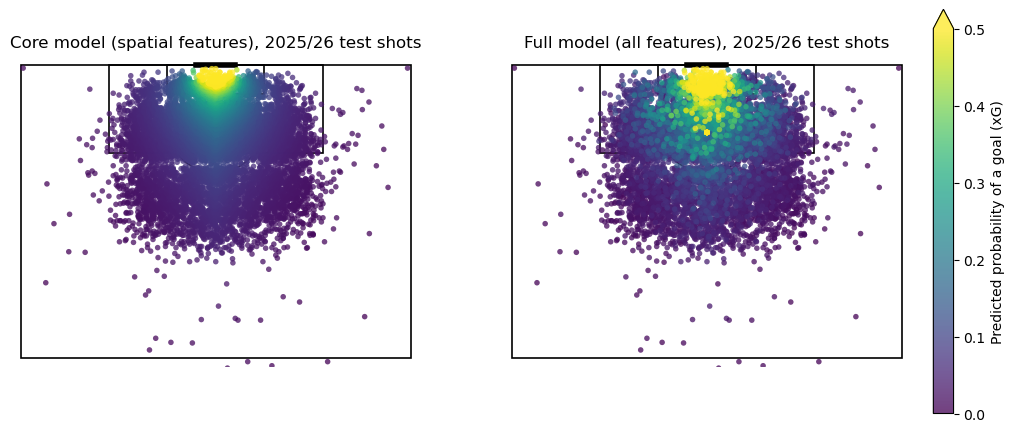

12 shots taken inside their own half are outside the plotted area.


In [14]:
def draw_half_pitch(ax):
    # Attacking half only, goal at the top. Horizontal axis = y, vertical axis = x.
    line = dict(fill=False, color="black", linewidth=1.2)
    ax.add_patch(Rectangle((0, 60), 80, 60, **line))          # pitch outline
    ax.add_patch(Rectangle((18, 102), 44, 18, **line))        # penalty area
    ax.add_patch(Rectangle((30, 114), 20, 6, **line))         # six yard box
    ax.add_patch(Arc((40, 108), 20, 20, theta1=217, theta2=323,
                     color="black", linewidth=1.2))           # penalty arc
    ax.scatter([40], [108], color="black", s=10, zorder=3)    # penalty spot
    ax.plot([36, 44], [120, 120], color="black", linewidth=4) # goal
    ax.set_xlim(-2, 82)
    ax.set_ylim(58, 122)
    ax.set_aspect("equal")
    ax.axis("off")


VMAX = 0.5
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, pred, title in zip(
    axes,
    [core_test_pred, full_test_pred],
    ["Core model (spatial features), 2025/26 test shots",
     "Full model (all features), 2025/26 test shots"],
):
    draw_half_pitch(ax)
    order = np.argsort(pred)   # draw high probability shots last
    sc = ax.scatter(
        test_df["y"].to_numpy()[order],
        test_df["x"].to_numpy()[order],
        c=pred[order], cmap="viridis", vmin=0, vmax=VMAX,
        s=16, alpha=0.75, edgecolors="none", zorder=4,
    )
    ax.set_title(title)

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.75, pad=0.02, extend="max")
cbar.set_label("Predicted probability of a goal (xG)")

plt.show()

n_hidden = int((test_df["x"] < 58).sum())
print(f"{n_hidden} shots taken inside their own half are outside the plotted area.")

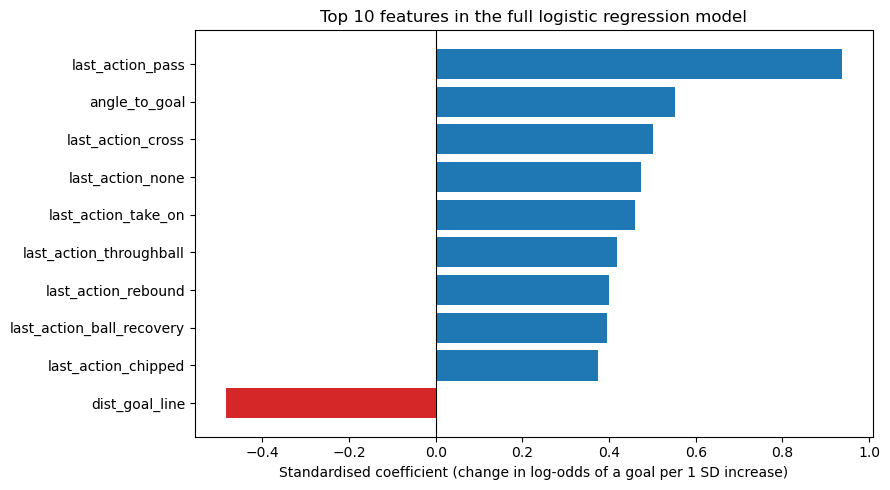

In [15]:
clf = full_final.named_steps["logit"]
coef = pd.Series(clf.coef_[0], index=FULL_FEATURES)   # coefficients on standardised features

# Ten largest by absolute size, keeping their sign
top10 = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10.index, top10.values,
        color=["tab:red" if v < 0 else "tab:blue" for v in top10.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardised coefficient (change in log-odds of a goal per 1 SD increase)")
ax.set_title("Top 10 features in the full logistic regression model")
fig.tight_layout()
plt.show()

## 8. Inference on the full model (unpenalised maximum likelihood)

The scikit-learn model above is built for prediction. To interpret the model and to test formally whether the extra features are worth including, the same logistic regression is refitted by unpenalised maximum likelihood with statsmodels. This gives standard errors, confidence intervals, p-values and a likelihood ratio test. The data are the same training + validation shots as the final models (Chapter 2 of [5]).

### 8.1 Build the design matrix

Unpenalised maximum likelihood needs a full rank design matrix and finite estimates, so some choices differ from the prediction model:

- **Reference categories:** Within each group of dummies one category must be dropped and its effect is absorbed into the intercept. The largest category is used as the baseline so odds ratios read as "compared with the typical shot": open play (shot situation), right foot (body part) and a pass (last action).
- **Redundant columns:** `score_diff` and `last_action_standard` are exact linear combinations of other columns (see section 5) and are dropped.
- **Pooled "other" last action:** The 80 foul shots (0 goals) and the shots with no last-action flag (rare categories removed in cleaning) are pooled into one `last_action_other` dummy, which has goals and so avoids separation.
- **Scaling:** Only the continuous features are standardised, so their odds ratios are *per 1 standard deviation*. Binary flags are left as 0/1, so their odds ratios are *for a shot with the flag vs without*.
- **Shot type structure:** `is_set_piece` is a superset flag that covers corners, direct free kicks and other set pieces, so `from_corner` and `is_free_kick` measure the *additional* effect over an other set piece. A corner's total effect compared with open play is the sum of the `is_set_piece` and `from_corner` coefficients.

In [16]:
tv = train_val_df.copy()

# Pool foul shots and shots with no last-action flag into one category
LAST = [c for c in tv.columns if c.startswith("last_action_")]
tv["last_action_other"] = ((tv[LAST].sum(axis=1) == 0) | (tv["last_action_foul"] == 1)).astype(int)
print(f"last_action_other: {int(tv['last_action_other'].sum())} shots, "
      f"{int(tv.loc[tv['last_action_other'] == 1, TARGET].sum())} goals")

# Reference categories (dropped) and continuous features (standardised)
REFERENCE = ["score_diff", "is_open_play", "right_foot", "last_action_pass", "last_action_standard"]
CONT = ["minute", "angle_to_goal", "dist_goal_line", "lateral_offset",
        "team_goals_before", "opp_goals_before"]
feat = [c for c in FULL_FEATURES if c not in REFERENCE] + ["last_action_other"]

# Standardise continuous features only; leave dummies as 0/1
X = tv[feat].astype(float)
X[CONT] = (X[CONT] - X[CONT].mean()) / X[CONT].std()
X = sm.add_constant(X)
y = tv[TARGET]

assert np.linalg.matrix_rank(X.to_numpy()) == X.shape[1], "design matrix not full rank"
print(f"Design matrix: {X.shape[0]:,} shots x {X.shape[1]} columns (including the constant), full rank")

last_action_other: 333 shots, 11 goals
Design matrix: 39,657 shots x 30 columns (including the constant), full rank


### 8.2 Fit the full and core models

Both models are fitted by Newton's method on identical shots. The core model uses the same (standardised) spatial columns, so it is nested inside the full model, which is what the likelihood-ratio test in section 8.4 requires. Convergence is asserted so a failed fit cannot pass silently. Note that the rest of this notebook in implementation of code learned from [6]. 

In [17]:
full_res = sm.Logit(y, X).fit(method="newton", maxiter=100, disp=False)
core_res = sm.Logit(y, sm.add_constant(X[CORE_FEATURES])).fit(method="newton", maxiter=100, disp=False)

assert full_res.mle_retvals["converged"], "full model did not converge"
assert core_res.mle_retvals["converged"], "core model did not converge"
print("Both models converged.")
print(f"Largest standard error in the full model: {full_res.bse.max():.3f}")

Both models converged.
Largest standard error in the full model: 0.425


### 8.3 Coefficient table

Coefficients are log-odds. The odds ratio is `exp(coefficient)`: values above 1 raise the odds of a goal and values below 1 lower them, holding the other features fixed. Standard errors and p-values assume shots are independent, which is optimistic because shots cluster within matches and players; read them as a guide to relative importance rather than exact significance.

In [18]:
ci = full_res.conf_int()
fit_summary = pd.DataFrame({
    "Coefficient": full_res.params,
    "Std. error": full_res.bse,
    "z": full_res.tvalues,
    "p-value": full_res.pvalues,
    "Odds ratio": np.exp(full_res.params),
    "OR 2.5%": np.exp(ci[0]),
    "OR 97.5%": np.exp(ci[1]),
}).drop(index="const")
fit_summary["Scale"] = ["per 1 SD" if c in CONT else "0 -> 1" for c in fit_summary.index]

pd.set_option("display.width", 200)
display(fit_summary.sort_values("z", key=abs, ascending=False).round(4))

,Coefficient,Std. error,z,p-value,Odds ratio,OR 2.5%,OR 97.5%,Scale
angle_to_goal,0.5521,0.0265,20.8337,0.0000,1.7368,1.6489,1.8294,per 1 SD
is_penalty,2.7353,0.1622,16.8585,0.0000,15.4140,11.2152,21.1847,0 -> 1
dist_goal_line,-0.4854,0.0332,-14.6361,0.0000,0.6155,0.5767,0.6568,per 1 SD
lateral_offset,-0.3556,0.0286,-12.4171,0.0000,0.7008,0.6625,0.7412,per 1 SD
last_action_aerial,-1.1697,0.1058,-11.0507,0.0000,0.3105,0.2523,0.3820,0 -> 1
last_action_throughball,0.8373,0.0852,9.8229,0.0000,2.3100,1.9546,2.7300,0 -> 1
head,-0.5655,0.0698,-8.1043,0.0000,0.5681,0.4955,0.6513,0 -> 1
last_action_other,-2.0694,0.3242,-6.3822,0.0000,0.1263,0.0669,0.2384,0 -> 1
last_action_cross,-0.4306,0.0694,-6.2062,0.0000,0.6501,0.5674,0.7448,0 -> 1
team_goals_before,0.0879,0.0186,4.7226,0.0000,1.0919,1.0528,1.1325,per 1 SD


### 8.4 Likelihood-ratio test: full vs core

The core model is a special case of the full model (the 26 extra coefficients all set to zero). Twice the difference in log-likelihood follows a chi-squared distribution with 26 degrees of freedom under that null hypothesis. AIC and BIC are also reported; both penalise extra parameters, BIC more heavily.

In [19]:
lr_stat = 2 * (full_res.llf - core_res.llf)
df_diff = int(full_res.df_model - core_res.df_model)
p_lr = stats.chi2.sf(lr_stat, df_diff)

comparison = pd.DataFrame({
    "Parameters": [int(core_res.df_model) + 1, int(full_res.df_model) + 1],
    "Log-likelihood": [core_res.llf, full_res.llf],
    "AIC": [core_res.aic, full_res.aic],
    "BIC": [core_res.bic, full_res.bic],
    "McFadden R2": [core_res.prsquared, full_res.prsquared],
}, index=["Core", "Full"])
display(comparison.round(4))

p_text = "p < 1e-300" if p_lr < 1e-300 else f"p = {p_lr:.2e}"
print(f"Likelihood-ratio test (full vs core): chi2 = {lr_stat:.1f}, df = {df_diff}, {p_text}")

,Parameters,Log-likelihood,AIC,BIC,McFadden R2
Core,4,-12251.2096,24510.4192,24544.7712,0.1071
Full,30,-11139.3385,22338.6770,22596.3177,0.1881


Likelihood-ratio test (full vs core): chi2 = 2223.7, df = 26, p < 1e-300


### 8.5 Odds-ratio plot

The 15 features with the largest |z| are shown as odds ratios with 95% confidence intervals on a log scale (the vertical line at 1 means no effect). Unlike ranking raw standardised coefficients, this puts binary and continuous features on an interpretable scale: continuous features are per 1 SD, binary features are 0 → 1 against the reference category (Chapter 3 of [5]).

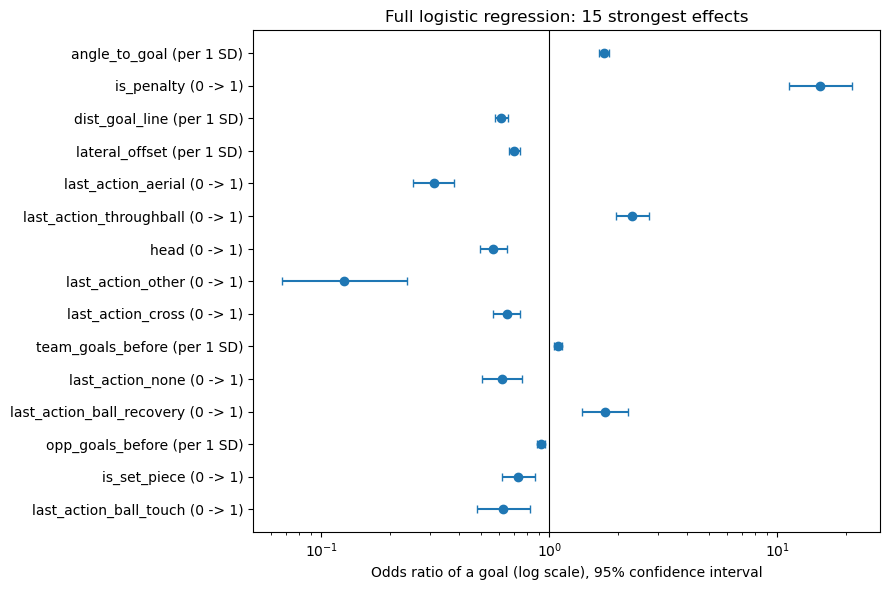

In [20]:
top = fit_summary.reindex(fit_summary["z"].abs().sort_values().index).tail(15)
labels = [f"{name} ({scale})" for name, scale in zip(top.index, top["Scale"])]

fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(
    top["Odds ratio"], range(len(top)),
    xerr=[top["Odds ratio"] - top["OR 2.5%"], top["OR 97.5%"] - top["Odds ratio"]],
    fmt="o", capsize=3,
)
ax.axvline(1, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_yticks(range(len(top)))
ax.set_yticklabels(labels)
ax.set_xlabel("Odds ratio of a goal (log scale), 95% confidence interval")
ax.set_title("Full logistic regression: 15 strongest effects")
fig.tight_layout()
plt.show()

## 9. Summary and limitations

**Main findings**

- **Full beats core on every metric, on both held-out seasons.** On the 2025/26 test season the full model lowers the Brier score by about 0.0085 and the log loss by about 0.026, and raises ROC-AUC by about 0.053. The ordering matches the 2024/25 validation season, so the result is not specific to one split.
- **Location alone gets part of the way.** The core model (distance, lateral offset, angle) ranks shots with an AUC of about 0.72. Shot type, body part, last action and game state add roughly 0.05 AUC.
- **The extra features are statistically justified.** The likelihood-ratio test of full vs core gives chi-squared of about 2,224 on 26 degrees of freedom (p < 1e-300), AIC and BIC are both lower for the full model, and McFadden R-squared rises from about 0.11 to about 0.19.
- **What drives xG.** Angle (odds ratio about 1.7 per SD) and distance (about 0.62 per SD) dominate among continuous features. A penalty multiplies the odds of a goal by about 15 compared with open play. Headers and aerial last actions lower the odds, and through balls raise them.
- **Rebounds.** Rebounds have a high raw goal rate, but their coefficient is close to zero once location is controlled for: they score because of where they are taken, not because they are rebounds.
- **Game state has small effects.** Goals scored by the team (odds ratio about 1.09 per SD) and by the opposition (about 0.92 per SD) shift the odds slightly. These are associations in a predictive model, not causal effects.

**Limitations**

- **Shots are not independent.** They cluster within matches and players, so the standard errors and p-values in section 8 are optimistic. They are a guide to relative importance, not exact significance.
- **Limited information per shot.** The event data contain no defender or goalkeeper positions, shot speed or placement, which caps how well any xG model built on them can perform.
- **Prediction model settings.** The scikit-learn model uses the default L2 penalty (`C = 1`) without tuning, and keeps two redundant columns (`score_diff`, `last_action_standard`) that only the penalty makes harmless. `last_action_foul` is excluded because of separation.
- **Small pooled category.** `last_action_other` is based on 333 shots (11 goals), so its odds ratio is imprecise and mainly a nuisance term. The rare last-action categories (tackle, lay-off, dispossessed) also have wide intervals.
- **Single split, point estimates.** The train / validation / test split is a single chronological split, and the test metrics are point estimates. Uncertainty (for example bootstrap confidence intervals), calibration and sensitivity to the penalty strength are not assessed in this notebook.
- **Interpretation.** Coefficients describe association in this league and these seasons; they should not be read causally or assumed to transfer to other competitions.

# References

[1] Gascon, A. (n.d.). xG Regression Model. GitHub. Available at: https://github.com/alexgasconn/xG-Regression-Model/ (Accessed: 24 October 2026).

[2] Soccermatics (n.d.). Fitting an xG model: Plotting shot location. Available at: https://soccermatics.readthedocs.io/en/latest/gallery/lesson2/plot_xGModelFit.html#plotting-shot-location (Accessed: 28 October 2026).

[3] 433charlie (n.d.). Football xG Model Build. GitHub. Available at: https://github.com/433charlie/Football-xG-Model-Build- (Accessed: 24 October 2026).

[4] grandngom (n.d.). xG-model-football. GitHub. Available at: https://github.com/grandngom/xG-model-football (Accessed: 30 October 2026)

[5] Hosmer, D.W., Lemeshow, S. and Sturdivant, R.X. (2013).
Applied Logistic Regression. 3rd edn. Wiley.
https://doi.org/10.1002/9781118548387

[6] statsmodels developers (n.d.).
LogitResults – statsmodels documentation.
https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.LogitResults.html